# 01 · Fase A — Disección instrumentada de Xception
**Proyecto:** Robustez de detectores de deepfakes: ¿Focal Loss mejora la robustez cross-manipulation de Xception?
**Curso:** 1INF52 Deep Learning (PUCP, 2026-2) · **Grupo 8**

Objetivo de esta fase: entender *por qué* Xception tiene la forma que tiene antes de intervenirla. Se mide:

1. Parámetros y FLOPs por bloque (stem / entry / middle / exit flow).
2. Convolución separable vs. convolución estándar equivalente.
3. Campo receptivo teórico vs. efectivo.
4. Latencia y memoria.
5. Activaciones intermedias y Grad-CAM sobre caras reales y falsas (requiere los recortes de FF++; se ejecuta en Kaggle).

Las secciones 1–4 no dependen de los datos: se calculan sobre la arquitectura con los pesos ImageNet. Todas las tablas y figuras se guardan en `results/teardown/`.

In [1]:
import sys, os, json, subprocess
from pathlib import Path
# Raíz del repo: funciona desde notebooks/kaggle/, desde la raíz o en Kaggle (clona el repo si falta)
REPO_URL = "https://github.com/Gredith/DeepLearning-G8-TA_Repository.git"
if Path("/kaggle").exists() and not Path("/kaggle/working/repo").exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, "/kaggle/working/repo"], check=True)
cands = [Path.cwd(), *list(Path.cwd().parents)[:2], Path("/kaggle/working/repo")]
ROOT = next(p for p in cands if (p / "src" / "kaggle_e2" / "teardown.py").exists())
sys.path.insert(0, str(ROOT / "src" / "kaggle_e2"))
OUT = ROOT / "results" / "teardown"; OUT.mkdir(parents=True, exist_ok=True)

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import teardown as T, plotstyle as S
S.apply(); pd.set_option("display.width", 160); pd.set_option("display.precision", 3)
torch.manual_seed(42); np.random.seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE, "| ROOT:", ROOT)

torch 2.14.1+cu130 | device: cpu | ROOT: /home/claude/repo


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0. Modelo base
Usamos `legacy_xception` de `timm`: es la Xception original de Chollet (2017), con los pesos ImageNet portados de la implementación que usa FaceForensics++. La cabeza de 1000 clases se reemplaza por una sola neurona (logit real/falso). La entrada nativa es 299×299 y la normalización es media 0.5 / desviación 0.5.

In [2]:
model = T.build_model(pretrained=True, num_classes=1)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parámetros totales: {n_params/1e6:.2f} M (backbone {(n_params-2049)/1e6:.2f} M + cabeza 2049)")
print("Configuración de entrada:", {k: model.default_cfg[k] for k in ["input_size", "mean", "std"]})

Parámetros totales: 20.81 M (backbone 20.81 M + cabeza 2049)
Configuración de entrada: {'input_size': (3, 299, 299), 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5)}


## 1. Parámetros y FLOPs por bloque
FLOPs contados con `torch.utils.flop_counter` (1 MAC = 2 FLOPs; solo conv/linear). Entrada 1×3×299×299.

In [3]:
df = T.params_flops_per_block(model, 299)
df.to_csv(OUT / "params_flops_por_bloque.csv", index=False)
df

,modulo,flow,params,GFLOPs,"salida (C,H,W)",% params,% FLOPs
0,conv1,stem,864,3.836e-02,"(32, 149, 149)",0.004,2.296e-01
1,conv2,stem,18432,7.966e-01,"(64, 147, 147)",0.089,4.767e+00
2,block1,entry,35264,1.227e+00,"(128, 74, 74)",0.170,7.340e+00
3,block2,entry,136064,1.204e+00,"(256, 37, 37)",0.654,7.206e+00
4,block3,entry,915944,2.120e+00,"(728, 19, 19)",4.403,1.269e+01
5,block4,middle,1613976,1.162e+00,"(728, 19, 19)",7.759,6.954e+00
6,block5,middle,1613976,1.162e+00,"(728, 19, 19)",7.759,6.954e+00
7,block6,middle,1613976,1.162e+00,"(728, 19, 19)",7.759,6.954e+00
8,block7,middle,1613976,1.162e+00,"(728, 19, 19)",7.759,6.954e+00
9,block8,middle,1613976,1.162e+00,"(728, 19, 19)",7.759,6.954e+00


In [4]:
flows = T.per_flow(df)
flows.to_csv(OUT / "params_flops_por_flow.csv")
print(f"Total: {df.params.sum()/1e6:.2f} M parámetros · {df.GFLOPs.sum():.2f} GFLOPs ({df.GFLOPs.sum()/2:.2f} GMACs) por imagen 299×299")
flows

Total: 20.80 M parámetros · 16.71 GFLOPs (8.36 GMACs) por imagen 299×299


,params,GFLOPs,% params,% FLOPs
flow,,,,
stem,19296,8.350e-01,0.093,4.997e+00
entry,1087272,4.551e+00,5.227,2.723e+01
middle,12911808,9.297e+00,62.071,5.564e+01
exit,6781216,2.028e+00,32.599,1.213e+01
head,2049,4.096e-06,0.010,2.451e-05


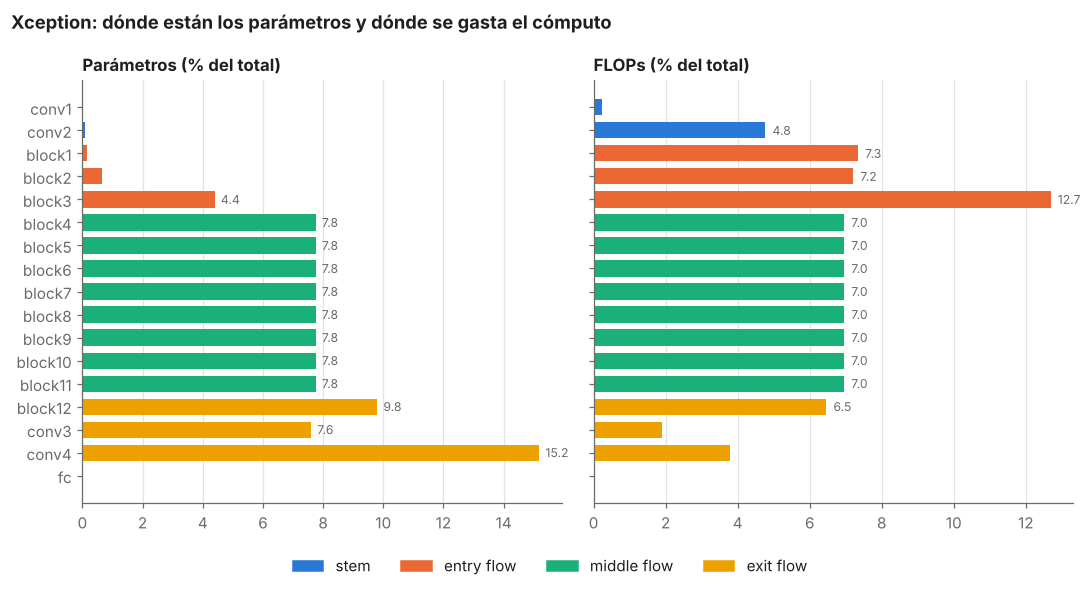

In [5]:
d = df[df.modulo != "global_pool"].iloc[::-1]
colors = [S.FLOW_COLORS[f] for f in d.flow]
fig, axes = plt.subplots(1, 2, figsize=(10, 5.2), sharey=True)
for ax, col, title in [(axes[0], "% params", "Parámetros (% del total)"), (axes[1], "% FLOPs", "FLOPs (% del total)")]:
    ax.barh(d.modulo, d[col], color=colors, height=0.7)
    ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False)
    for y, v in enumerate(d[col]):
        if v >= 4: ax.text(v + 0.2, y, f"{v:.1f}", va="center", fontsize=8, color=S.MUTED)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for f, c in S.FLOW_COLORS.items() if f != "head"]
fig.legend(handles, ["stem", "entry flow", "middle flow", "exit flow"], loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Xception: dónde están los parámetros y dónde se gasta el cómputo", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(OUT / "fig_params_flops.png"); plt.show()

**Lectura.**
- **Parámetros y cómputo no están en el mismo sitio.** El *exit flow* tiene ~33 % de los parámetros pero solo ~12 % de los FLOPs: trabaja sobre mapas de 10×10. El *entry flow* es al revés: ~5 % de los parámetros y ~27 % de los FLOPs, porque opera a alta resolución (147→19 px). El stem solo (`conv2`, una convolución estándar 3×3 sobre 147×147) ya gasta casi 5 % del cómputo con 0.1 % de los parámetros.
- **El middle flow es el núcleo:** 8 bloques idénticos (728 canales, 19×19, sin cambio de resolución) concentran ~62 % de los parámetros y ~56 % de los FLOPs.
- **Consecuencia para el proyecto:** la intervención de la Fase B (la pérdida) no toca la arquitectura, así que el costo de inferencia es idéntico entre BCE y Focal Loss. Si más adelante se prueba la ablación secundaria (rama de alta frecuencia SRM en el stem), el costo extra se concentraría en la zona de alta resolución, que es la más cara por parámetro.

## 2. Convolución separable vs. estándar
Se construye la *misma* red reemplazando cada `SeparableConv2d` (depthwise 3×3 + pointwise 1×1) por una `Conv2d` 3×3 estándar con las mismas entradas y salidas, y se mide de nuevo.

In [6]:
sep = T.separable_vs_standard(model, 299)
sep.to_csv(OUT / "separable_vs_estandar.csv", index=False)
sep

,variante,params (M),GFLOPs,factor vs separable
0,Xception (separable),20.809,16.711,1.000
1,Misma red con conv estándar 3x3,177.025,137.633,8.236


**Lectura.** Con convoluciones estándar la red tendría ~8.5× más parámetros (~177 M) y ~8.2× más FLOPs. Para 728 canales y kernel 3×3, la separable cuesta $C\cdot 9 + C^2$ frente a $9C^2$: un ahorro cercano a 9× cuando $C$ es grande. Esa es la "forma" de Xception: profundidad (36 capas convolucionales) con un presupuesto parecido al de Inception-v3.

Esto importa para la detección de deepfakes. La convolución depthwise filtra **cada canal por separado en el espacio**, y la pointwise mezcla canales sin mirar el espacio. Es un sesgo inductivo favorable a detectar patrones de textura locales por canal, que es justamente lo que dejan los generadores. Es plausible que Xception sea buena *in-domain* precisamente por eso, y que por eso mismo memorice la huella de un generador concreto. Lo pondremos a prueba en la Fase C.

## 3. Campo receptivo teórico vs. efectivo
- **Teórico:** $r_{out} = r_{in} + (k-1)\,d\,j_{in}$, $j_{out} = j_{in}\cdot s$, por la rama principal (los atajos 1×1 no lo amplían).
- **Efectivo (ERF, Luo et al. 2016):** gradiente $|\partial y_{centro}/\partial x|$ de la unidad central de cada capa respecto a la entrada, promediado sobre 8 entradas. Reportamos el lado del cuadrado centrado que contiene el 50 % y el 95 % de esa masa. Aquí se mide con ruido gaussiano; en Kaggle se repite con recortes de caras (sección 5).

In [7]:
rf = T.theoretical_receptive_field(model)
layers = ["block1", "block2", "block3", "block5", "block7", "block9", "block11", "block12", "conv4"]
erf_maps, erf = T.effective_receptive_field(model, layers, 299, n_samples=8)
rf_all = rf.merge(erf.rename(columns={"capa": "modulo"}), on="modulo", how="left")
rf_all.to_csv(OUT / "campo_receptivo.csv", index=False)
rf_all

,modulo,flow,RF teórico (px),stride acumulado,lado ERF 95% (px),lado ERF 50% (px)
0,conv1,stem,3,2,NaN,NaN
1,conv2,stem,7,2,NaN,NaN
2,block1,entry,19,4,17.0,9.0
3,block2,entry,43,8,31.0,15.0
4,block3,entry,91,16,57.0,25.0
5,block4,middle,187,16,NaN,NaN
6,block5,middle,283,16,123.0,43.0
7,block6,middle,379,16,NaN,NaN
8,block7,middle,475,16,177.0,59.0
9,block8,middle,571,16,NaN,NaN


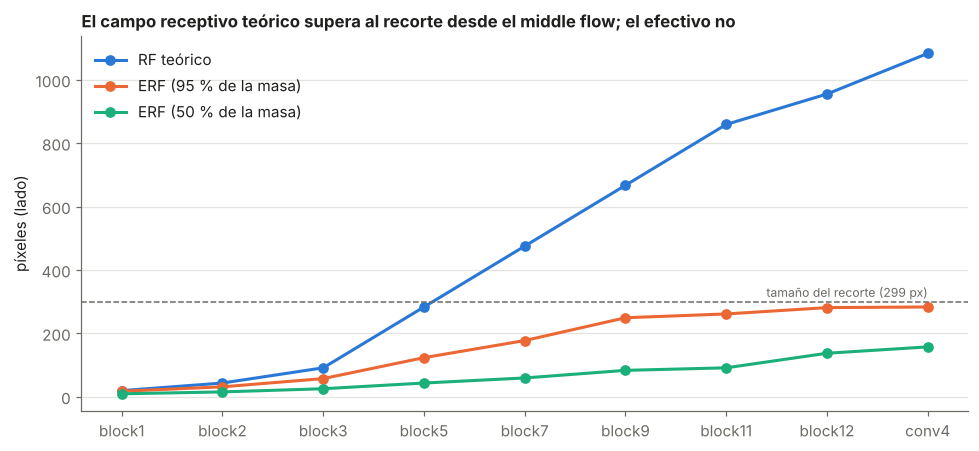

In [8]:
r = rf_all.dropna()
x = np.arange(len(r))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(x, r["RF teórico (px)"], marker="o", ms=6, color=S.SERIES[0], label="RF teórico")
ax.plot(x, r["lado ERF 95% (px)"], marker="o", ms=6, color=S.SERIES[1], label="ERF (95 % de la masa)")
ax.plot(x, r["lado ERF 50% (px)"], marker="o", ms=6, color=S.SERIES[2], label="ERF (50 % de la masa)")
ax.axhline(299, color=S.MUTED, lw=1, ls="--"); ax.text(len(r) - 1, 315, "tamaño del recorte (299 px)", ha="right", color=S.MUTED, fontsize=8)
ax.set_xticks(x, r.modulo); ax.set_ylabel("píxeles (lado)"); ax.grid(axis="x", visible=False)
ax.set_title("El campo receptivo teórico supera al recorte desde el middle flow; el efectivo no", loc="left")
ax.legend(loc="upper left"); plt.tight_layout(); plt.savefig(OUT / "fig_campo_receptivo.png"); plt.show()

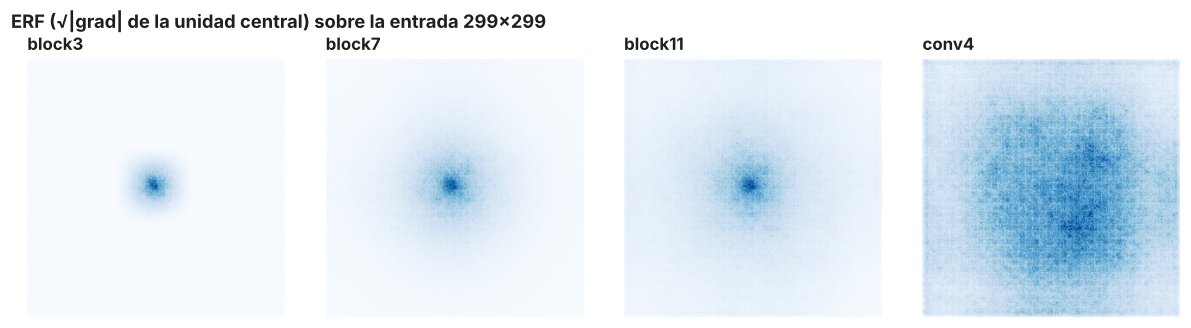

In [9]:
show = ["block3", "block7", "block11", "conv4"]
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, n in zip(axes, show):
    ax.imshow(erf_maps[n] ** 0.5, cmap="Blues"); ax.set_title(n, loc="left"); ax.axis("off")
fig.suptitle("ERF (√|grad| de la unidad central) sobre la entrada 299×299", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "fig_erf_mapas.png"); plt.show()

**Lectura.**
- El RF teórico crece 96 px por bloque en el middle flow (3 separables 3×3 con stride acumulado 16). Ya en `block5` (283 px) cubre casi todo el recorte, y en la salida llega a 1083 px, más de 3.5× la imagen.
- El ERF es mucho menor. En el middle flow, la mitad de la sensibilidad se concentra en un cuadrado central de ~45–90 px (`block5`→`block11`), aunque el RF teórico sea de 283–859 px. Solo al final (`block12`, `conv4`) el 95 % de la masa cubre casi todo el recorte, y aun así el 50 % sigue en ~140–160 px. El RF teórico es una cota; lo que la red usa de verdad está concentrado cerca del centro y decae de forma aproximadamente gaussiana.
- **Hipótesis para la Fase C:** si el detector decide con información relativamente local (ERF pequeño frente a la cara), es coherente que se apoye en artefactos de textura y de borde de mezcla propios del generador de entrenamiento. Con Grad-CAM verificaremos si la atención se concentra en la zona de mezcla (contorno de la cara) o en la textura interna, y si Focal Loss la desplaza.
- *Limitación:* este ERF se mide con ruido gaussiano y pesos ImageNet. El ERF sobre caras y tras el fine-tuning puede ser distinto; lo repetimos en la sección 5.

## 4. Latencia y memoria
CPU: la máquina donde se ejecuta este notebook. GPU: solo si hay CUDA (Kaggle T4/P100); esa es la cifra que se reporta en el póster.

In [10]:
lat = [T.latency_ms(model, 299, batch=1, device="cpu", runs=20),
       T.latency_ms(model, 299, batch=8, device="cpu", warmup=2, runs=5)]
if DEVICE == "cuda":
    name = torch.cuda.get_device_name(0)
    for b in (1, 32):
        r_ = T.latency_ms(model, 299, batch=b, device="cuda", runs=50); r_["device"] = f"cuda ({name})"; lat.append(r_)
lat = pd.DataFrame(lat); lat.to_csv(OUT / f"latencia_{DEVICE}.csv", index=False)
print("CPU threads:", torch.get_num_threads()); lat

CPU threads: 2


,device,batch,input,mediana_ms,p90_ms,ms_por_imagen
0,cpu,1,299,130.890,159.53,130.890
1,cpu,8,299,1355.255,1376.98,169.407


In [11]:
mem = {"pesos fp32 (MB)": n_params * 4 / 2**20,
       "activaciones fp32, batch 1 (MB, cota)": T.activation_memory_mb(model.cpu(), 299, 1)}
mem["activaciones fp32, batch 32 (MB, cota)"] = mem["activaciones fp32, batch 1 (MB, cota)"] * 32
if DEVICE == "cuda":
    mem["pico GPU entrenamiento AMP, batch 32 (MB, medido)"] = T.gpu_peak_memory_mb(model, 299, 32, train=True)
mem = pd.Series(mem).round(1); mem.to_csv(OUT / f"memoria_{DEVICE}.csv"); mem

pesos fp32 (MB)                             79.4
activaciones fp32, batch 1 (MB, cota)      281.8
activaciones fp32, batch 32 (MB, cota)    9019.0
dtype: float64

**Lectura.** Los pesos ocupan ~80 MB, pero las activaciones que el entrenamiento guarda para el backward son ~3.5× más por imagen (~280 MB en fp32 como cota). Por eso el tamaño de batch en la T4 (16 GB) está limitado por las activaciones y no por los pesos, y por eso entrenamos con precisión mixta (AMP). La mayor parte de esa memoria la generan las capas de alta resolución del stem y del entry flow, es decir, las mismas que dominan el costo por parámetro.

## 5. Activaciones intermedias, ERF sobre caras y Grad-CAM *(Kaggle)*
Requiere `crops/` generado por `02_preprocesamiento_ffpp.ipynb` y, para Grad-CAM, un checkpoint de `03_entrenamiento_bce_vs_focal.ipynb`. Si no existen, la celda se salta.

> **Licencia:** esta celda muestra caras de FF++ (tag `caras`). Antes de subir el notebook ejecutado a GitHub, correr `python tools/limpiar_caras.py`. Las figuras se guardan en archivos ignorados por Git; las tablas numéricas (`erf_sobre_caras.csv`) sí se versionan.

In [ ]:
import glob
from PIL import Image
CROPS = Path(os.environ.get("CROPS_DIR", "/kaggle/working/crops"))
if not CROPS.exists():
    print("No hay recortes en", CROPS, "→ ejecutar en Kaggle después del preprocesamiento.")
else:
    import gradcam, data as D
    tf = D.eval_transform(299)
    pick = {"real": sorted(glob.glob(str(CROPS / "original" / "*" / "*.png")))[:4],
            "Deepfakes": sorted(glob.glob(str(CROPS / "Deepfakes" / "*" / "*.png")))[:4]}
    imgs = {k: torch.stack([tf(Image.open(p).convert("RGB")) for p in v]) for k, v in pick.items()}
    # 5a. activaciones medias por capa
    lay = ["conv2", "block1", "block3", "block7", "block12"]
    fig, axes = plt.subplots(2, len(lay) + 1, figsize=(13, 4.6))
    for row, (k, x) in enumerate(imgs.items()):
        acts = T.intermediate_activations(model.cpu(), x[:1], lay)
        axes[row, 0].imshow((x[0].permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1)); axes[row, 0].set_title(k, loc="left")
        for c, n in enumerate(lay):
            axes[row, c + 1].imshow(acts[n][0], cmap="magma"); axes[row, c + 1].set_title(n, loc="left")
    for a in axes.flat: a.axis("off")
    plt.tight_layout(); plt.savefig(OUT / "fig_activaciones_real_vs_fake.png"); plt.show()
    # 5b. ERF sobre caras reales
    _, erf_faces = T.effective_receptive_field(model.cpu(), ["block3", "block7", "block11", "conv4"], inputs=torch.cat(list(imgs.values())))
    erf_faces.to_csv(OUT / "erf_sobre_caras.csv", index=False); display(erf_faces)
    # 5c. Grad-CAM con el checkpoint entrenado (si existe)
    for ck in sorted((ROOT / "results" / "checkpoints").glob("*.pt")):
        m = T.build_model(False, 1); m.load_state_dict(torch.load(ck, map_location="cpu")["model"])
        fig = gradcam.grid(m, imgs, title=ck.stem); fig.savefig(OUT / f"fig_gradcam_{ck.stem}.png"); plt.show()

## Resumen para el cuaderno de decisiones
| Medición | Resultado | Implicación |
|---|---|---|
| Tamaño | 20.8 M parámetros, 16.7 GFLOPs (8.4 GMACs) a 299×299 | Viable en Kaggle con AMP |
| Dónde están los parámetros | middle flow 62 %, exit 33 % | El núcleo repetido domina la capacidad |
| Dónde está el cómputo | entry 27 %, middle 56 % | La alta resolución es cara por parámetro |
| Separable vs estándar | ×8.5 parámetros, ×8.2 FLOPs si fuera estándar | Sesgo hacia textura local por canal |
| RF teórico / ERF 50 % | middle flow: 283–859 px / 45–90 px; salida: 1083 px / ~160 px | Los bloques intermedios miran regiones locales |
| Pérdida (Fase B) | No cambia params, FLOPs ni latencia | La comparación BCE vs Focal es justa en costo |